In [ ]:
# Shared bootstrap for notebooks organized by world.
from pathlib import Path
import os, sys
_here = Path.cwd().resolve()
_roots = ( _here, *_here.parents )
_root = next((p for p in _roots if (p / 'pyproject.toml').is_file() and (p / 'src').is_dir()), None)
if _root is None: raise FileNotFoundError('Launch Jupyter from inside the research repository')
if str(_root) not in sys.path: sys.path.insert(0, str(_root))
os.chdir(_root / 'notebooks')  # preserve paths from older notebooks
print('Repository root:', _root)


# Five-seed curriculum comparison
**Question:** Does staged training outperform mixed and reverse schedules in binding **efficiency**, final ID accuracy, and OOD generalization?

Uses the `schedule_comparison.json` generated by the 3,000-step plateau-curriculum trainer. All results here are **development** results, not held-out test results. Paired comparisons use the same random seeds and fixed-final checkpoints. No configuration tuning is performed in this notebook.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent
RESULTS_PATH = PROJECT_ROOT / 'outputs/medium_world/experiments/plateau_five_seeds/schedule_comparison.json'

result = json.loads(RESULTS_PATH.read_text(encoding='utf-8'))
runs = [r for r in result['runs'] if r.get('status') == 'completed']
TASKS = ['color', 'shape', 'conjunction', 'pair']
SCHEDULES = ['mixed', 'staged', 'reverse']
print('Source:', RESULTS_PATH)
print('Completed runs:', len(runs), '| Seeds:', sorted({r['seed'] for r in runs}))
print('Training configuration:', result.get('config', {}))

Source: c:\Users\Quoc Thai\Downloads\AI\AIO\Conquer\AIO Conquer 5 - visual_world\The-order-of-Learning\outputs\medium_world\experiments\plateau_five_seeds\schedule_comparison.json
Completed runs: 15 | Seeds: [42, 43, 44, 45, 46]
Training configuration: {'seeds': [42, 43, 44, 45, 46], 'schedules': ['mixed', 'staged', 'reverse'], 'main_epochs': 12, 'common_epochs': 3, 'batch_size': 50, 'eval_every': 100, 'lr': 0.0001, 'weight_decay': 0.0, 'scheduler': 'ReduceLROnPlateau', 'scheduler_factor': 0.5, 'scheduler_patience': 3, 'scheduler_threshold': 0.001, 'scheduler_metric': 'fixed ID-dev overall cross-entropy', 'min_lr': 1e-06, 'scheduler_reset': 'none (continuous within each run)', 'dim': 48, 'patch_size': 4, 'augmentation': True, 'primary_metric': 'fixed-final ID-dev pair accuracy', 'efficiency_metric': 'ID-dev pair AULC (steps 0 to final)', 'ood_metric': 'fixed-final OOD-dev pair accuracy', 'checkpoint_policy': 'best overall ID-dev CE; primary analysis fixed-final'}


## 1. Experimental integrity
Verify that the same seeds and tasks are represented, and that the total training budget and per-task example exposures are matched. **Matched exposure does not imply identical LR trajectories**, because the scheduler is adaptive.

In [ ]:
integrity = pd.DataFrame([{
    'seed': r['seed'], 'schedule': r['schedule'], 'steps': r['steps_run'],
    'presentations': r['exposure_plan']['total_presentations'],
    **{f'exposure_{t}': r['exposure_plan']['counts_by_template'][t] for t in TASKS},
    'lr_reductions': len(r.get('lr_reductions', [])),
    'final_lr': r['final'].get('lr', np.nan)
} for r in runs]).sort_values(['seed', 'schedule']).reset_index(drop=True)

expected = {(seed, schedule) for seed in result['config']['seeds'] for schedule in SCHEDULES}

for col in ['steps','presentations'] + [f'exposure_{t}' for t in TASKS]:
    assert integrity[col].nunique() == 1, f'Unequal training exposure: {col}'
print('All runs have equal updates and task exposure. Scheduler reductions may still differ.')
display(integrity)

All runs have equal updates and task exposure. Scheduler reductions may still differ.


,seed,schedule,steps,presentations,exposure_color,exposure_shape,exposure_conjunction,exposure_pair,lr_reductions,final_lr
0,42,mixed,3000,150000,37500,37500,37500,37500,0,0.000100
1,42,reverse,3000,150000,37500,37500,37500,37500,0,0.000100
2,42,staged,3000,150000,37500,37500,37500,37500,2,0.000025
3,43,mixed,3000,150000,37500,37500,37500,37500,0,0.000100
4,43,reverse,3000,150000,37500,37500,37500,37500,3,0.000013
5,43,staged,3000,150000,37500,37500,37500,37500,2,0.000025
6,44,mixed,3000,150000,37500,37500,37500,37500,0,0.000100
7,44,reverse,3000,150000,37500,37500,37500,37500,5,0.000003
8,44,staged,3000,150000,37500,37500,37500,37500,3,0.000013
9,45,mixed,3000,150000,37500,37500,37500,37500,0,0.000100


## 2. Final metrics per seed
Use **fixed-final** checkpoints for the main comparison, not each schedule's best checkpoint (which may occur at different steps). Accuracy is shown in percentages; AULC remains on a 0–1 scale.

In [3]:
records = []
for r in runs:
    f = r['final']
    records.append({'seed': r['seed'], 'schedule': r['schedule'],
                    'overall_id': 100*f['id_dev']['accuracy'],
                    'ood_pair': 100*f['ood_dev']['by_template'].get('pair', f['ood_dev']['accuracy']),
                    'pair_aulc': r['id_pair_aulc'],
                    'id_ce': f['id_dev']['loss'], 'best_id_step': r['best_id_dev_step'],
                    **{t: 100*f['id_dev']['by_template'][t] for t in TASKS}})
final = pd.DataFrame(records).sort_values(['seed','schedule']).reset_index(drop=True)
metrics = ['overall_id','color','shape','conjunction','pair','ood_pair','pair_aulc']
means = final.groupby('schedule')[metrics].agg(['mean','std']).reindex(SCHEDULES)
print('Mean ± sample SD across the five paired seeds:')
display(means.round(3))
print('Per-seed fixed-final metrics:')
display(final[['seed','schedule'] + metrics].round(3))

Mean ± sample SD across the five paired seeds:


overall_id          color           shape        conjunction         \
               mean    std    mean     std    mean    std        mean    std   
schedule                                                                       
mixed        72.461  2.391  96.797   4.362  61.328  1.325      78.125  3.747   
staged       71.680  2.351  95.156   3.989  60.469  1.446      76.953  4.479   
reverse      63.633  6.329  79.219  12.901  56.250  5.116      66.250  7.697   

            pair        ood_pair        pair_aulc         
            mean    std     mean    std      mean    std  
schedule                                                  
mixed     53.594  2.726     54.2  1.980     0.530  0.010  
staged    54.141  3.783     52.3  5.515     0.521  0.009  
reverse   52.812  1.689     51.7  2.287     0.514  0.015

Per-seed fixed-final metrics:


,seed,schedule,overall_id,color,shape,conjunction,pair,ood_pair,pair_aulc
0,42,mixed,74.414,98.828,63.281,80.078,55.469,54.75,0.533
1,42,reverse,71.777,97.656,58.984,76.953,53.516,55.50,0.531
2,42,staged,72.949,98.438,61.328,80.078,51.953,49.50,0.516
3,43,mixed,73.242,99.609,62.109,80.078,51.172,53.00,0.534
4,43,reverse,64.453,79.688,61.719,64.453,51.953,50.50,0.522
5,43,staged,69.531,91.406,62.109,72.266,52.344,52.00,0.519
6,44,mixed,72.559,98.047,60.547,80.078,51.562,57.00,0.516
7,44,reverse,54.785,62.891,49.219,55.469,51.562,49.50,0.497
8,44,staged,72.266,98.047,59.375,80.859,50.781,52.25,0.509
9,45,mixed,73.730,98.438,60.156,78.906,57.422,51.75,0.542


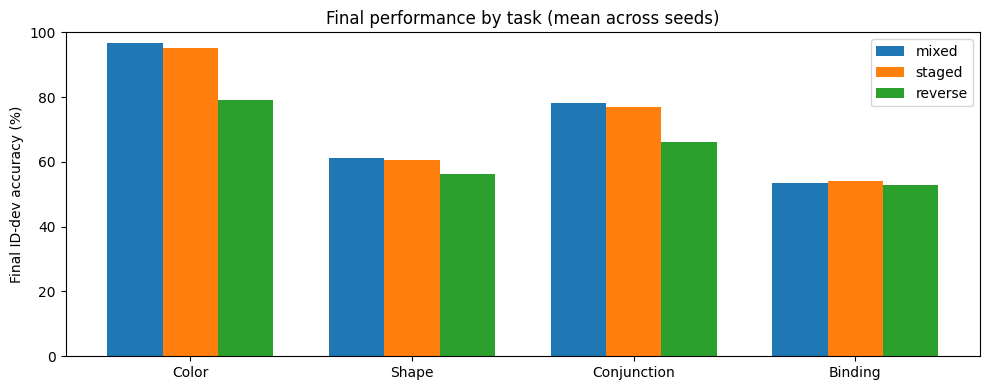

In [4]:
fig, ax = plt.subplots(figsize=(10,4))
by = final.groupby('schedule')[TASKS].mean().reindex(SCHEDULES)
x = np.arange(len(TASKS)); width = 0.25
for j, schedule in enumerate(SCHEDULES):
    ax.bar(x + (j-1)*width, by.loc[schedule], width, label=schedule)
ax.set_xticks(x, ['Color','Shape','Conjunction','Binding']); ax.set_ylabel('Final ID-dev accuracy (%)')
ax.set_ylim(0,100);ax.legend();ax.set_title('Final performance by task (mean across seeds)')
plt.tight_layout();plt.show()

## 3. Paired differences across seeds
A positive difference means the first named schedule performs better. The 95% intervals below are **seed-resampling percentile bootstrap intervals** (10,000 draws, resampling paired seeds), provided as descriptive uncertainty estimates. With only five seeds, don't interpret them as a proof of significance.

In [5]:
rng = np.random.default_rng(7)
comparisons = [('staged','mixed'),('reverse','mixed'),('staged','reverse')]
rows = []
for a,b in comparisons:
    for metric in ['pair','pair_aulc','overall_id','ood_pair','shape','conjunction']:
        pivot = final.pivot(index='seed', columns='schedule', values=metric)
        diff = (pivot[a] - pivot[b]).to_numpy()
        boot = rng.choice(diff, size=(10000, len(diff)), replace=True).mean(axis=1)
        lo, hi = np.percentile(boot, [2.5,97.5])
        rows.append({'comparison':f'{a} − {b}', 'metric':metric, 'mean_delta':diff.mean(),
                     'sd_delta':diff.std(ddof=1),'CI_low':lo,'CI_high':hi,
                     'seeds_positive':int((diff>0).sum()),'n_seeds':len(diff)})
paired = pd.DataFrame(rows)
display(paired.round(4))
print('Binding differences, by seed:')
display(final.pivot(index='seed',columns='schedule',values='pair').assign(
    staged_minus_mixed=lambda x:x['staged']-x['mixed']).round(3))

,comparison,metric,mean_delta,sd_delta,CI_low,CI_high,seeds_positive,n_seeds
0,staged − mixed,pair,0.5469,2.7427,-1.6406,2.5781,3,5
1,staged − mixed,pair_aulc,-0.0091,0.0097,-0.0156,-0.0009,1,5
2,staged − mixed,overall_id,-0.7812,1.8835,-2.3438,0.5664,2,5
3,staged − mixed,ood_pair,-1.9000,6.8433,-6.2500,3.9000,1,5
4,staged − mixed,shape,-0.8594,1.2166,-1.7969,0.0781,1,5
5,staged − mixed,conjunction,-1.1719,3.7263,-4.5312,0.7031,3,5
6,reverse − mixed,pair,-0.7812,3.3716,-3.5156,1.6406,2,5
7,reverse − mixed,pair_aulc,-0.0163,0.0160,-0.0299,-0.0055,0,5
8,reverse − mixed,overall_id,-8.8281,6.7229,-14.0234,-3.6328,0,5
9,reverse − mixed,ood_pair,-2.5000,3.2548,-5.1500,-0.2000,1,5


Binding differences, by seed:


schedule,mixed,reverse,staged,staged_minus_mixed
seed,,,,
42,55.469,53.516,51.953,-3.516
43,51.172,51.953,52.344,1.172
44,51.562,51.562,50.781,-0.781
45,57.422,51.562,60.156,2.734
46,52.344,55.469,55.469,3.125


## 4. Learning curves and learning efficiency
The learning-curve area is the mean binding accuracy over the entire training budget, **including the period before a stage has seen binding data**. It measures end-to-end learning efficiency; it is not a measure of how quickly the binding-only stage optimizes.

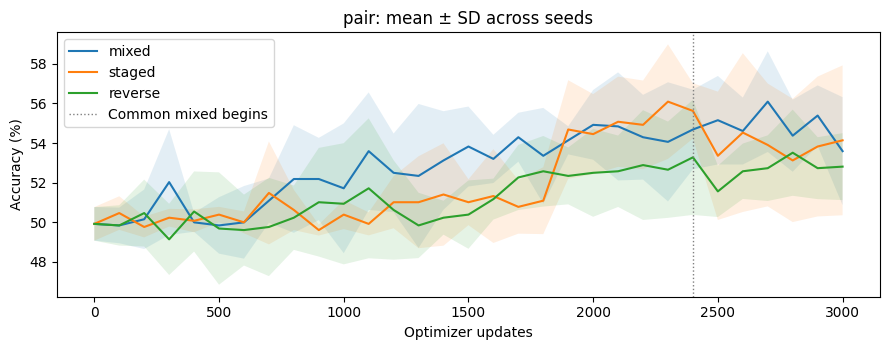

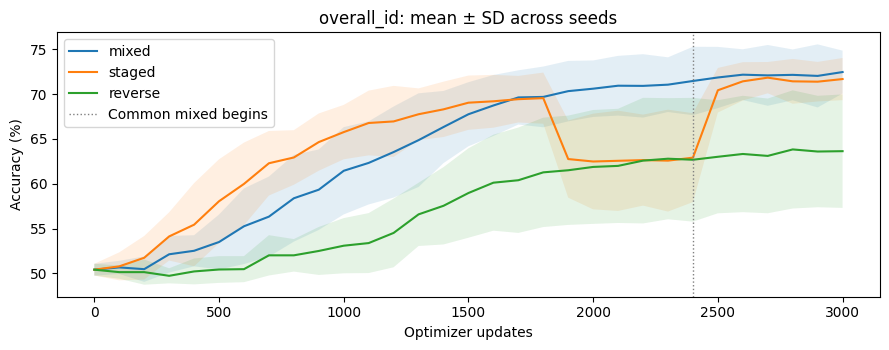

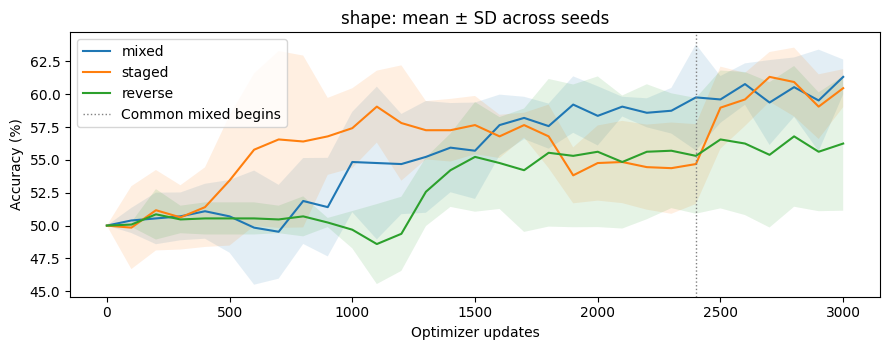

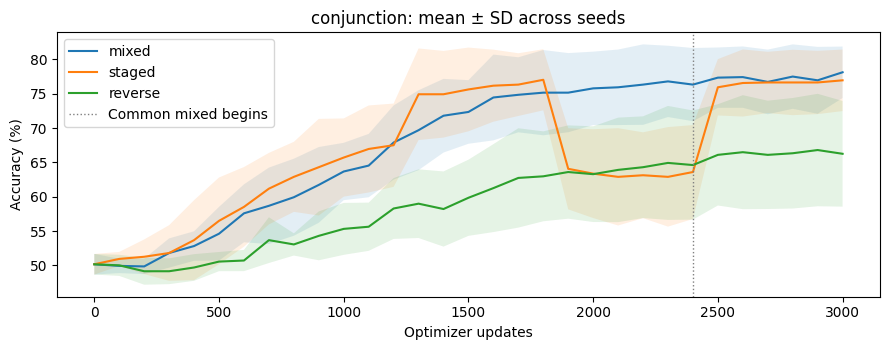

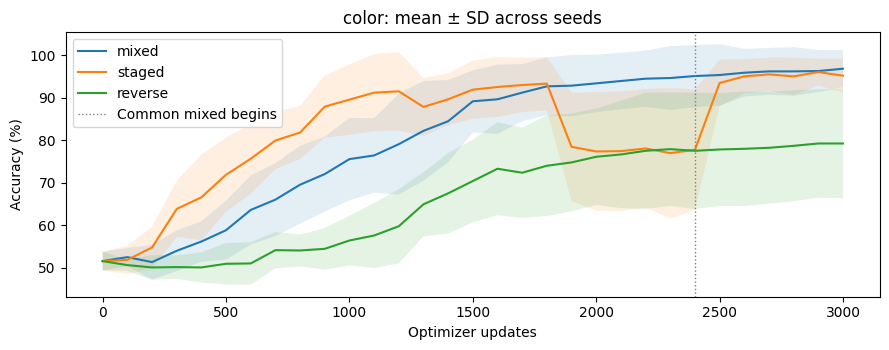

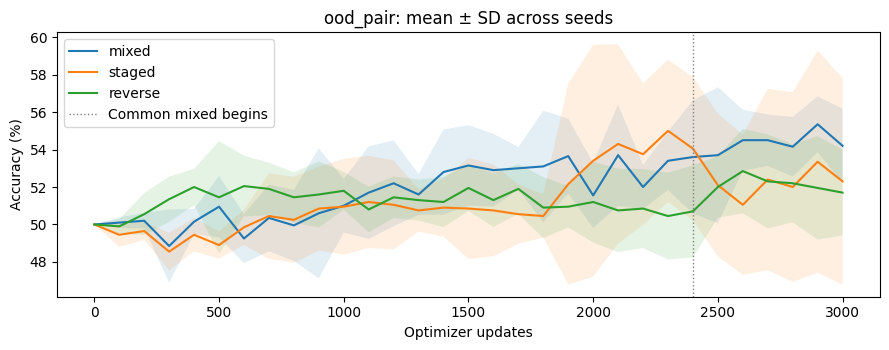

In [6]:
history_rows = []
for r in runs:
    for h in r['history']:
        history_rows.append({'seed':r['seed'],'schedule':r['schedule'],'step':h['step'],
            'phase':h['phase'],'overall_id':100*h['id_dev']['accuracy'],
            'id_ce':h['id_dev']['loss'], 'ood_pair':100*h['ood_dev']['accuracy'],
            'lr':h.get('lr', np.nan),
            **{t:100*h['id_dev']['by_template'][t] for t in TASKS}})
history = pd.DataFrame(history_rows).sort_values(['schedule','seed','step'])
for metric in ['pair','overall_id','shape','conjunction','color','ood_pair']:
    fig, ax = plt.subplots(figsize=(9,3.6))
    for schedule in SCHEDULES:
        chunk = history[history.schedule==schedule]
        curve = chunk.groupby('step')[metric].agg(['mean','std']).sort_index()
        ax.plot(curve.index,curve['mean'], label=schedule)
        ax.fill_between(curve.index.to_numpy(),(curve['mean']-curve['std']).to_numpy(),
                        (curve['mean']+curve['std']).to_numpy(),alpha=.12)
    ax.axvline(2400,ls=':',color='gray',lw=1,label='Common mixed begins')
    ax.set_xlabel('Optimizer updates');ax.set_ylabel('Accuracy (%)')
    ax.set_title(f'{metric}: mean ± SD across seeds');ax.legend(loc='best');plt.tight_layout();plt.show()

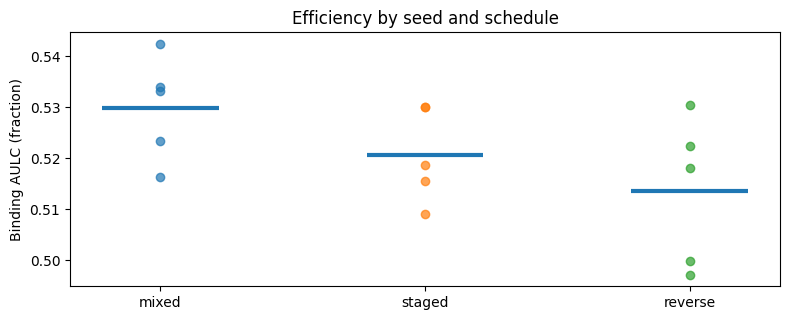

In [7]:
fig, ax = plt.subplots(figsize=(8,3.3))
for schedule in SCHEDULES:
    selected = final[final.schedule==schedule]['pair_aulc']
    ax.scatter([schedule]*len(selected),selected,alpha=.7)
    ax.hlines(selected.mean(),SCHEDULES.index(schedule)-0.22,SCHEDULES.index(schedule)+0.22,lw=3)
ax.set_ylabel('Binding AULC (fraction)');ax.set_title('Efficiency by seed and schedule')
plt.tight_layout();plt.show()

## 5. Phase transitions: transfer and forgetting
Compare each staged/reverse transition's **last evaluation before the switch** with the first evaluation **after 100 updates** on the new phase. A negative delta for a previously learned task is evidence of short-term forgetting. This is an observational comparison; recovery can occur later.

In [8]:
transition_rows = []
for r in runs:
    hs = sorted(r['history'],key=lambda h:h['step'])
    for old, new in zip(hs[:-1],hs[1:]):
        if old['phase'] != new['phase'] and old['phase'] != 'initial':
            transition_rows.append({'seed':r['seed'],'schedule':r['schedule'],
                'transition':f"{old['phase']} → {new['phase']}",
                'step_before':old['step'],'step_after':new['step'],
                **{f'delta_{t}':100*(new['id_dev']['by_template'][t]-old['id_dev']['by_template'][t])
                   for t in TASKS},
                'delta_overall':100*(new['id_dev']['accuracy']-old['id_dev']['accuracy'])})
transitions = pd.DataFrame(transition_rows)
if len(transitions):
    display(transitions.groupby(['schedule','transition'])[
        ['delta_color','delta_shape','delta_conjunction','delta_pair','delta_overall']].mean().round(2))
    print('Per-seed transition changes:')
    display(transitions.round(2))
else:
    print('No transitions found in the saved histories.')

delta_color  delta_shape  \
schedule transition                                            
mixed    mixed → common_mixed              0.23        -0.16   
reverse  attributes → common_mixed         0.31         1.25   
         binding → conjunction             3.12        -0.08   
         conjunction → attributes          5.16         3.20   
staged   attributes → conjunction         -3.67        -0.55   
         binding → common_mixed           15.70         4.30   
         conjunction → binding           -14.84        -2.97   

                                    delta_conjunction  delta_pair  \
schedule transition                                                 
mixed    mixed → common_mixed                    1.02        0.47   
reverse  attributes → common_mixed               1.48       -1.72   
         binding → conjunction                   2.97        0.16   
         conjunction → attributes                0.70       -0.78   
staged   attributes → conjunction                7.42        0.00   
         binding → common_mixed                 12.34       -2.27   
         conjunction → binding                 -12.97        3.59   

                                    delta_overall  
schedule transition                                
mixed    mixed → common_mixed                0.39  
reverse  attributes → common_mixed           0.33  
         binding → conjunction               1.54  
         conjunction → attributes            2.07  
staged   attributes → conjunction            0.80  
         binding → common_mixed              7.52  
         conjunction → binding              -6.80

Per-seed transition changes:


,seed,schedule,transition,step_before,step_after,delta_color,delta_shape,delta_conjunction,delta_pair,delta_overall
0,42,mixed,mixed → common_mixed,2400,2500,0.00,-2.34,1.17,1.56,0.10
1,42,staged,attributes → conjunction,1200,1300,-13.67,-0.39,13.67,0.39,0.00
2,42,staged,conjunction → binding,1800,1900,-29.69,-5.47,-25.00,5.08,-13.77
3,42,staged,binding → common_mixed,2400,2500,29.30,1.56,24.22,-4.30,12.70
4,42,reverse,binding → conjunction,600,700,3.12,0.00,5.47,1.95,2.64
5,42,reverse,conjunction → attributes,1200,1300,7.03,7.03,0.78,-2.34,3.12
6,42,reverse,attributes → common_mixed,2400,2500,0.78,1.17,0.39,-4.30,-0.49
7,43,mixed,mixed → common_mixed,2400,2500,-0.39,-3.91,0.78,3.52,0.00
8,43,staged,attributes → conjunction,1200,1300,-1.17,-2.73,0.39,-2.73,-1.56
9,43,staged,conjunction → binding,1800,1900,-13.28,0.39,-8.20,2.34,-4.69


## 6. Adaptive learning rates as a possible confound
The schedules share the initial LR and scheduler rules, but can have **different realized LR values** because validation loss evolves differently. Examine this before claiming the accuracy differences are caused exclusively by task order.

lr_reductions          final_lr                   
                  mean min max      mean       min      max
schedule                                                   
mixed              0.0   0   0  0.000100  0.000100  0.00010
staged             1.8   1   3  0.000032  0.000013  0.00005
reverse            2.2   0   5  0.000038  0.000003  0.00010

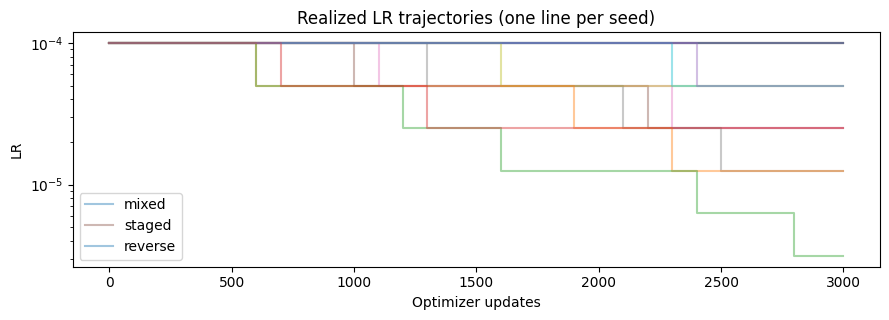

In [9]:
lr_info = integrity.groupby('schedule')[['lr_reductions','final_lr']].agg(['mean','min','max']).reindex(SCHEDULES)
display(lr_info)
fig, ax = plt.subplots(figsize=(9,3.3))
for schedule in SCHEDULES:
    for seed, sub in history[history.schedule==schedule].groupby('seed'):
        ax.step(sub['step'], sub['lr'],where='post',alpha=.42,
                label=schedule if seed==min(result['config']['seeds']) else None)
ax.set_yscale('log');ax.set_xlabel('Optimizer updates');ax.set_ylabel('LR')
ax.set_title('Realized LR trajectories (one line per seed)');ax.legend();plt.tight_layout();plt.show()